# 01 — Mirage replication on Qwen3-VL-4B (VQA-RAD)

**Question.** Ben-Levi et al. (*Mirage Probes*, arXiv 2606.13870) show mirage behaviour is linearly decodable in Qwen3-VL-32B / Ovis-2B, with their with-minus-without-image "Diff" probe at **96% on VQA-RAD** (LogReg on the with-image state: 72%). Does that hold at 4B, is the Diff number partly the no-image *response text* echoing the label, and what does the with/without-image geometry look like?

**Pipeline.** Their generator unchanged (`scripts/data/gen_mutations_get_responses.py`, their system prompt, their 4 GPT-4o-mini paraphrases from `data/final_data/mutations.json`, greedy, 512 tokens) served by vLLM; our extractor `miragelab/extract.py`; analysis in `miragelab/analysis.py`.

**Labels** (on the *without-image* reply): `admit` = acknowledges missing image/uncertainty; `mirage` = no acknowledgement and same answer as with-image (BoW cos ≥ .7); `neutral` = rest. `label` = their regex + extra admission phrasings (`label_paper` = theirs verbatim).

**Poolings.** `last_prompt` = residual at the assistant-header token, before any answer token exists. `text_mean` = the paper's pooling: mean over all non-special text tokens *including the model's own reply*.

In [1]:
import sys, subprocess, numpy as np, pandas as pd, matplotlib.pyplot as plt
import os; BENCH = os.environ.get('MIRAGE_ROOT', '..'); sys.path.insert(0, '..')  # BENCH: data root with runs/
from miragelab import analysis as A
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', '../tests'], cwd='..', capture_output=True, text=True).stdout[-300:])
import os; RUN = os.environ.get('MIRAGE_RUN', BENCH + '/runs/full')
full = A.records(RUN)          # every generated record: behaviour rates
df, acts, meta = A.load(RUN)   # extracted subset: all mirage + neutral, admits sampled
print('generated', len(full), '| extracted', len(df), df.label.value_counts().to_dict())
L = meta['layers']
print('records', df.shape, '| acts [rec, cond(with,no), pool(last_prompt,text_mean), layer, d] =', acts.shape)
print('layers', L)
df.head(3)

....................                               [100%]
42 passed in 7.96s

generated 5950 | extracted 1800 {'admit': 1094, 'neutral': 376, 'mirage': 330}
records (1800, 19) | acts [rec, cond(with,no), pool(last_prompt,text_mean), layer, d] = (1800, 2, 2, 18, 2560)
layers [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36]


,uid,variant,question,gt,category,with_resp,no_resp,with_correct,no_correct,with_pred,no_pred,label_paper,label,no_commits,outcome,split,image_id,modality,prior_correct
0,vqa_rad_0,mutation_1,is there any indication of an aortic aneurysm?,yes,binary,The image shows a chest radiograph with a pace...,To determine whether there is an indication of...,False,False,no,no,admit,admit,True,None,None,None,None,None
1,vqa_rad_2,mutation_1,Are there any intraparenchymal abnormalities i...,no,binary,The image shows a chest radiograph with a note...,To determine whether there are intraparenchyma...,True,True,no,no,admit,admit,True,None,None,None,None,None
2,vqa_rad_3,mutation_1,are the kidneys visible in this image?,no,binary,The kidneys are not clearly visible in this im...,To determine whether the kidneys are visible i...,True,True,no,no,admit,admit,True,None,None,None,None,None


## 1. Behaviour (all generated records)
**Methods.** Accuracy of the parsed `[[answer]]` vs ground truth (yes/no closed questions, test split), with Wilson 95% CIs. Label counts under the paper's regex and ours.

,condition,k,n,acc,lo,hi
0,with image,3893,5950,0.654,0.642,0.666
1,without image,3231,5950,0.543,0.530,0.556


label,admit,mirage,neutral,All
label_paper,,,,
admit,4121,0,0,4121
mirage,354,330,0,684
neutral,769,0,376,1145
All,5244,330,376,5950


admit replies that still commit to an [[answer]]: 92.5%


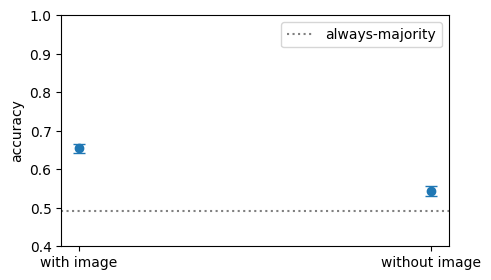

In [2]:
rows = []
for cond, col in [('with image', 'with_correct'), ('without image', 'no_correct')]:
    s = full[col].dropna(); rows.append((cond, int(s.sum()), len(s), *A.wilson(int(s.sum()), len(s))))
acc = pd.DataFrame(rows, columns=['condition', 'k', 'n', 'acc', 'lo', 'hi']).round(3); display(acc)
display(pd.crosstab(full.label_paper, full.label, margins=True))
print('admit replies that still commit to an [[answer]]:', f"{full[full.label=='admit'].no_commits.mean():.1%}")
fig, ax = plt.subplots(figsize=(5, 3))
ax.errorbar(acc.condition, acc.acc, yerr=[acc.acc - acc.lo, acc.hi - acc.acc], fmt='o', capsize=4)
ax.axhline(full['gt'].eq('yes').mean(), ls=':', c='grey', label='always-majority')
ax.set_ylim(0.4, 1); ax.set_ylabel('accuracy'); ax.legend(); plt.show()

In [3]:
pd.set_option('display.max_colwidth', 400)
for lab in ['mirage', 'admit', 'neutral']:
    print(f'===== {lab}')
    for _, r in full[full.label == lab].sample(3, random_state=0).iterrows():
        print('Q:', r.question, '| GT:', r['gt'], '\n  NO-IMG:', r.no_resp[-350:].replace('\n', ' '), '\n')

===== mirage
Q: is there evidence of free peritoneal fluid? | GT: no 
  NO-IMG: a CT or X-ray image, I would look for these signs.  **In this case, based on the visual evidence in the image (as per the VQA-RAD dataset), there is no clear evidence of free peritoneal fluid.** The abdominal cavity appears normal, with no fluid levels, no fluid bands, and no displacement of bowel loops or other signs of fluid accumulation.  [[No]] 

Q: Is the patient lying on their back? | GT: yes 
  NO-IMG: heir normal anatomical positions without significant rotation or distortion. If the patient were lying on their side, the diaphragm or organs would appear shifted or compressed.  Given that this is a radiology image (likely a chest or abdominal X-ray), and assuming standard imaging protocols, the patient is most likely lying on their back.  [[Yes]] 

Q: does the gastrointestinal contrast highlight the small bowel? | GT: yes 
  NO-IMG: ed to highlight the small bowel. If the image shows a radiopaque, co

**Results.** Accuracy 65.4% [64.2, 66.6] with image, 54.3% [53.0, 55.6] without; always-majority ~51%. 88% of no-image replies admit the image is missing; 92.5% of those still give a final answer (the system prompt forbids refusing). The paper's regex labels 684 mirages; 354 say "cannot view the actual image" or similar (8/8 checked by hand), leaving 330 (5.5%).

**Discussion.** On this model the paper's labeling roughly doubles the mirage count. Mirages sit on prior-answerable questions (no-image accuracy 72% on mirage records vs 53% on admits).

## 2. Probes by layer — replicating Table 1 (VQA-RAD column) plus controls
**Methods.** Binary `mirage` (1) vs `admit` (0); neutral dropped. All mirage rows kept, admit subsampled to 3× (seed 0). Logistic probe (standardised, C=0.1, class-balanced), 5-fold **StratifiedGroupKFold over leak groups** (connected components of base question and normalised question text: 482 texts recur across base questions, so grouping by base question alone let identical inputs straddle folds); metric = balanced accuracy, mean ± sd over folds.

| probe | features | role |
|---|---|---|
| A | with-image `text_mean` | paper's LogReg (Qwen-32B: 72%) |
| B | with − without `text_mean` | paper's Diff (Qwen-32B: 96%) |
| C | without-image `text_mean` only | **echo check**: B minus the image. If C ≈ B, the Diff probe reads the no-image reply text, which *defines* the label |
| D | without-image `last_prompt` | pre-answer: is the mirage decided before the first token? |
| E | with − without `last_prompt` | Diff without any reply tokens |
| B-shuf | B with permuted labels | chance control |

In [4]:
rng = np.random.default_rng(0)
m_idx = np.where(df.label == 'mirage')[0]; a_idx = np.where(df.label == 'admit')[0]
a_idx = rng.choice(a_idx, min(len(a_idx), 3 * len(m_idx)), replace=False)
idx = np.sort(np.r_[m_idx, a_idx]); y = (df.label.values[idx] == 'mirage').astype(int); g = A.leak_groups(df.uid.values[idx], df.question.map(A.norm_text).values[idx])   # no identical text or base question across folds
print('probe set: mirage', y.sum(), 'admit', (1 - y).sum(), 'base questions', len(set(g)))
W, N, LP, TM = 0, 1, 0, 1
feats = {
    'A with text_mean':        lambda j: acts[idx, W, TM, j],
    'B diff text_mean':        lambda j: acts[idx, W, TM, j].astype('f4') - acts[idx, N, TM, j],
    'C no-img text_mean':      lambda j: acts[idx, N, TM, j],
    'D no-img last_prompt':    lambda j: acts[idx, N, LP, j],
    'E diff last_prompt':      lambda j: acts[idx, W, LP, j].astype('f4') - acts[idx, N, LP, j],
}
res = []
for j, l in list(enumerate(L))[1::2]:   # every other saved layer (CPU budget)
    for name, f in feats.items():
        res.append((name, l, *A.probe_cv(f(j), y, g)))
    res.append(('B-shuf', l, *A.probe_cv(feats['B diff text_mean'](j), y, g, shuffle_labels=True)))
res = pd.DataFrame(res, columns=['probe', 'layer', 'bacc', 'sd'])
res.pivot(index='layer', columns='probe', values='bacc').round(3)

probe set: mirage 330 admit 990 base questions 765


probe,A with text_mean,B diff text_mean,B-shuf,C no-img text_mean,D no-img last_prompt,E diff last_prompt
layer,,,,,,
4,0.641,0.915,0.488,0.900,0.680,0.648
8,0.638,0.928,0.502,0.918,0.667,0.656
12,0.656,0.932,0.508,0.915,0.683,0.699
16,0.673,0.937,0.499,0.920,0.709,0.704
20,0.694,0.935,0.497,0.922,0.740,0.720
24,0.687,0.933,0.523,0.921,0.744,0.737
28,0.691,0.926,0.500,0.925,0.735,0.733
32,0.670,0.921,0.509,0.913,0.725,0.730
36,0.679,0.920,0.491,0.911,0.713,0.712


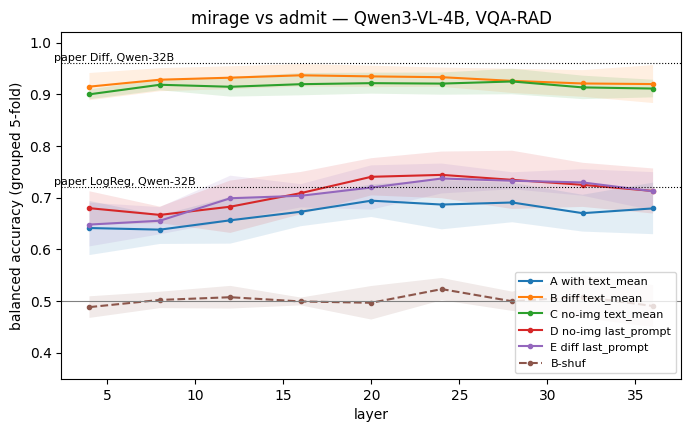

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, d in res.groupby('probe', sort=False):
    ax.plot(d.layer, d.bacc, marker='o', ms=3, label=name, ls='--' if 'shuf' in name else '-')
    ax.fill_between(d.layer, d.bacc - d.sd, d.bacc + d.sd, alpha=.12)
ax.axhline(.96, c='k', lw=.8, ls=':'); ax.text(L[0], .965, 'paper Diff, Qwen-32B', fontsize=8)
ax.axhline(.72, c='k', lw=.8, ls=':'); ax.text(L[0], .725, 'paper LogReg, Qwen-32B', fontsize=8)
ax.axhline(.5, c='grey', lw=.8)
ax.set_xlabel('layer'); ax.set_ylabel('balanced accuracy (grouped 5-fold)'); ax.set_ylim(.35, 1.02)
ax.legend(fontsize=8, loc='lower right'); ax.set_title('mirage vs admit — Qwen3-VL-4B, VQA-RAD'); plt.show()

**Results** (folds = leak groups; 765 groups in the probe set). A (with-image text_mean) peaks 0.69 (L20) — the paper's Qwen-32B LogReg is 0.72. B (paper's Diff) 0.94 (L16) vs their 0.96. **C (no-image text_mean alone) 0.92–0.93, within 0.02 of B at every layer.** D (no-image pre-answer, no reply tokens) 0.74 (L24); E 0.74. Shuffled 0.49–0.52.

**Discussion.** The replication holds at 4B. But B ≈ C: the Diff probe's accuracy comes from the no-image reply, which contains the admission words that define the label. The number for "is the mirage decision encoded before the model speaks" is D ≈ 0.74: real, well above chance, far below 0.96.

## 3. Geometry
**Why several embeddings.** PCA keeps global linear structure (what a linear probe/steering vector sees) but crushes nonlinear structure; t-SNE shows local clusters but distorts distances between them; PHATE (diffusion-based) keeps both local neighbourhoods and the global/continuous *progression* structure — the right tool if mirage vs admit is a gradient rather than two blobs. Same points, same colours, three views.

**Methods.** Layer = best layer of probe D. Points = without-image `last_prompt` states (pre-answer), up to 1500 sampled rows, all mirage rows kept.

layer used: 24


~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 28 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/phate/phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 2.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


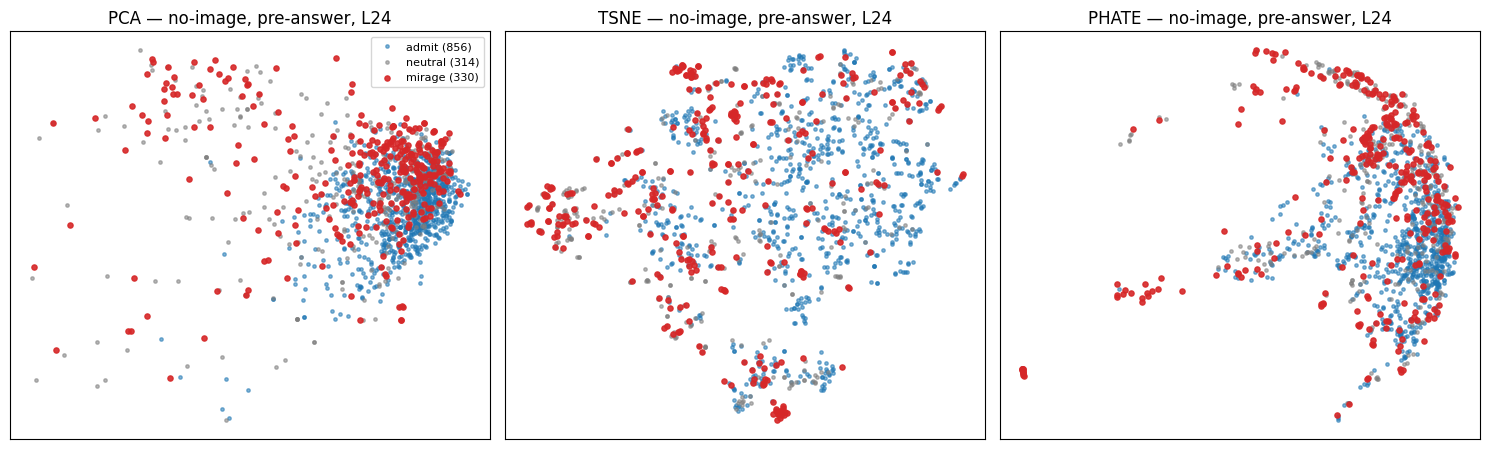

In [6]:
dD = res[res.probe == 'D no-img last_prompt']; lay = int(dD.layer.values[dD.bacc.values.argmax()]); jD = L.index(lay)
print('layer used:', lay)
sel = np.sort(np.r_[m_idx, rng.choice(np.setdiff1d(np.arange(len(df)), m_idx), min(1500, len(df)) - len(m_idx), replace=False)])
X = np.asarray(acts[sel, N, LP, jD], 'f4'); lab = df.label.values[sel]
col = {'mirage': 'tab:red', 'admit': 'tab:blue', 'neutral': 'tab:grey'}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, meth in zip(axs, ['pca', 'tsne', 'phate']):
    Z = A.embed(X, meth)
    for k in ['admit', 'neutral', 'mirage']:
        s = lab == k; ax.scatter(Z[s, 0], Z[s, 1], s=6 if k != 'mirage' else 14, c=col[k], alpha=.55 if k != 'mirage' else .9, label=f'{k} ({s.sum()})')
    ax.set_title(f'{meth.upper()} — no-image, pre-answer, L{lay}'); ax.set_xticks([]); ax.set_yticks([])
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3a'. The steering view: 1-D projection on the mirage direction (held-out)
**Methods.** Diff-of-means direction (mirage − admit) fit on half of the base questions; histogram of the *other* half projected onto it. This is exactly the axis a steering vector would push along — if the two histograms overlap, a vector built this way cannot separate them no matter what the 2-D maps show.

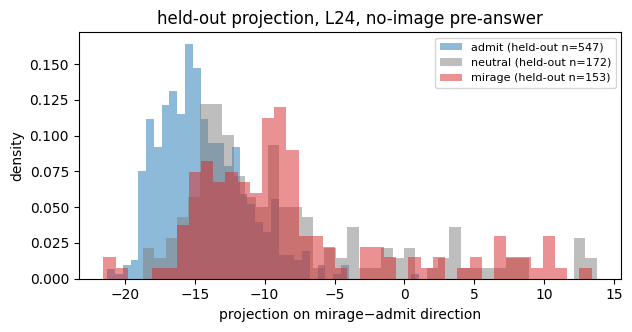

In [7]:
uq = np.array(sorted(set(df.uid))); half = set(rng.choice(uq, len(uq) // 2, replace=False))
tr = np.array([u in half for u in df.uid]); keep = df.label.isin(['mirage', 'admit']).values
Xall = np.asarray(acts[:, N, LP, jD], 'f4'); yall = (df.label == 'mirage').values
v = A.diff_of_means(Xall[tr & keep], yall[tr & keep])
fig, ax = plt.subplots(figsize=(7, 3.2))
for k in ['admit', 'neutral', 'mirage']:
    s = (~tr) & (df.label == k).values
    if s.sum() < 2 or not np.isfinite(v).all(): print('skip', k, s.sum()); continue
    ax.hist(Xall[s] @ v, bins=40, density=True, alpha=.5, color=col[k], label=f'{k} (held-out n={s.sum()})')
ax.set(xlabel='projection on mirage−admit direction', ylabel='density', title=f'held-out projection, L{lay}, no-image pre-answer'); ax.legend(fontsize=8); plt.show()

### 3b. With-image vs without-image: arrows
**Methods.** One PHATE fit on both conditions' `last_prompt` states (same records). Arrow = no-image point → its own with-image point, for 60 mirage and 60 admit records. Hypotheses from the paper: *textual-bias* mirages ignore the image (short arrows); *spurious-image* mirages already sit where image-present states sit.

~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/graphtools/graphs.py:803: RuntimeWarning: Detected zero distance between samples 713 and 1334. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/phate/phate.py:919: RuntimeWarning: Graph is disconnected with 2 connected components. This may indicate that your knn parameter (currently 5) is too small, or that your data contains distinct clusters. PHATE may not accurately represent relationships between disconnected components.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by -4.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.


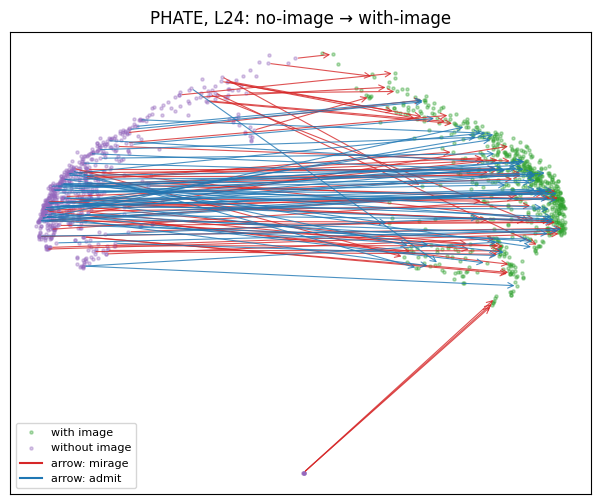

In [8]:
ar = np.r_[rng.choice(m_idx, min(60, len(m_idx)), replace=False), rng.choice(np.where(df.label == "admit")[0], min(60, (df.label == "admit").sum()), replace=False)]
base = np.sort(np.r_[ar, rng.choice(len(df), min(600, len(df)), replace=False)]); base = np.unique(base)
Xb = np.r_[np.asarray(acts[base, W, LP, jD], 'f4'), np.asarray(acts[base, N, LP, jD], 'f4')]
Z = A.embed(Xb, 'phate'); Zw, Zn = Z[:len(base)], Z[len(base):]
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(Zw[:, 0], Zw[:, 1], s=5, c='tab:green', alpha=.35, label='with image')
ax.scatter(Zn[:, 0], Zn[:, 1], s=5, c='tab:purple', alpha=.35, label='without image')
pos = {r: i for i, r in enumerate(base)}
for r in ar:
    i = pos[r]; c = col[df.label.values[r]]
    ax.annotate('', Zw[i], Zn[i], arrowprops=dict(arrowstyle='->', color=c, lw=.8, alpha=.8))
ax.plot([], [], c='tab:red', label='arrow: mirage'); ax.plot([], [], c='tab:blue', label='arrow: admit')
ax.legend(fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f'PHATE, L{lay}: no-image → with-image'); plt.show()

### 3b'. PCA of the displacement vectors Δh = h(with) − h(without)
**Methods.** The paper's Diff probe lives on Δh, not on either state. PCA of Δh coloured by label: do mirages get a *different kind* of image update (direction), or just a smaller one (length, 3c)?

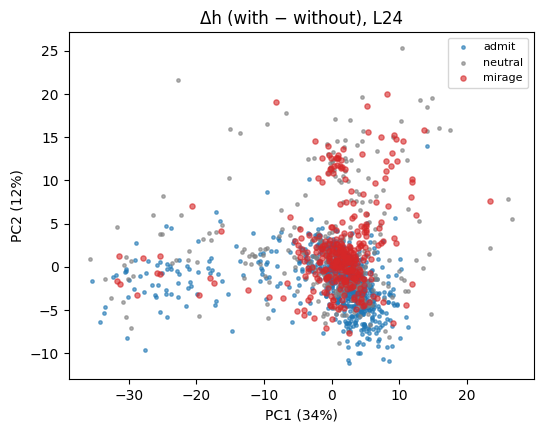

In [9]:
from sklearn.decomposition import PCA
D = np.asarray(acts[sel, W, LP, jD], 'f4') - np.asarray(acts[sel, N, LP, jD], 'f4')
pca = PCA(2).fit(D); Zd = pca.transform(D)
fig, ax = plt.subplots(figsize=(6, 4.5))
for k in ['admit', 'neutral', 'mirage']:
    s = lab == k; ax.scatter(Zd[s, 0], Zd[s, 1], s=6 if k != 'mirage' else 14, c=col[k], alpha=.6, label=k)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%})', title=f'Δh (with − without), L{lay}'); ax.legend(fontsize=8); plt.show()

### 3c. How far does the image move the state, per layer? And do mirages 'look image-present'?
**Methods.** (i) Arrow length = cosine distance between a record's with- and without-image `last_prompt` state, per layer, median + IQR by label. (ii) Image-presence score: project each no-image state onto the unit direction mean(with) − mean(no) (computed on all records), centred at mean(no). A *spurious-image* regime predicts mirages score higher than admits.

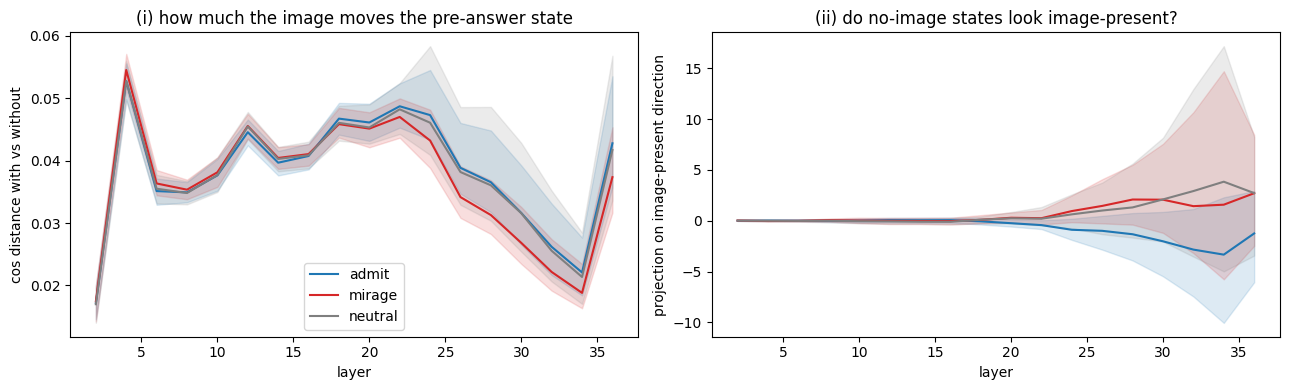

In [10]:
def cosd(a, b):
    a = np.asarray(a, 'f4'); b = np.asarray(b, 'f4')
    return 1 - (a * b).sum(-1) / np.linalg.norm(a, axis=-1) / np.linalg.norm(b, axis=-1)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for k in ['admit', 'mirage', 'neutral']:
    ii = np.where(df.label == k)[0]
    d = np.stack([cosd(acts[ii, W, LP, j], acts[ii, N, LP, j]) for j in range(len(L))])
    q = np.percentile(d, [25, 50, 75], axis=1)
    axs[0].plot(L, q[1], c=col[k], label=k); axs[0].fill_between(L, q[0], q[2], color=col[k], alpha=.15)
    s = []
    for j in range(len(L)):
        mw, mn = acts[:, W, LP, j].astype('f4').mean(0), acts[:, N, LP, j].astype('f4').mean(0)
        u = (mw - mn) / np.linalg.norm(mw - mn); s.append((np.asarray(acts[ii, N, LP, j], 'f4') - mn) @ u)
    s = np.stack(s); q = np.percentile(s, [25, 50, 75], axis=1)
    axs[1].plot(L, q[1], c=col[k], label=k); axs[1].fill_between(L, q[0], q[2], color=col[k], alpha=.15)
axs[0].set(xlabel='layer', ylabel='cos distance with vs without', title='(i) how much the image moves the pre-answer state')
axs[1].set(xlabel='layer', ylabel='projection on image-present direction', title='(ii) do no-image states look image-present?')
axs[0].legend(); plt.tight_layout(); plt.show()

## 4. Discussion

- **Replicated:** mirage is linearly decodable in Qwen3-VL-4B; LogReg 0.69 and Diff 0.94 vs the paper's Qwen-32B VQA-RAD 0.72 / 0.96.
- **The 0.94 is mostly echo.** Pooling over the reply lets the probe read the admission text that defines the label (C ≈ B). Pre-answer states give 0.74.
- **Labels:** the paper's regex misses common admissions; half its mirages on this model are admissions.
- **Leakage check:** 482 question texts recur across base questions; regrouping folds by text + base question changed probe numbers by ≤0.02.
- **Geometry (L24, no-image, pre-answer):** mirages overlap the admit cloud in PCA/t-SNE; in PHATE they gather along the outer arc — a shift, not a separate cluster. Held-out projection: shifted, overlapping.
- **Image effect:** the image moves mirage pre-answer states slightly less than admit states at L24–32; no-image mirage states lean toward the image-present direction while admits lean away (wide spread). Weak evidence for both of the paper's regimes.
- **Limits:** yes/no answers make the paper's same-answer criterion largely chance agreement (notebook 02); one model; greedy decoding.